In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
df=pd.read_csv("/kaggle/input/wine-quality-binary-classification/wine.csv")
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,bad
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,bad
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,bad
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,good
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,bad
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,bad
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,good
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,good
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,bad


In [3]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   object 
dtypes: float64(11), object(1)
memory usage: 150.0+ KB


In [5]:
df["quality"].unique()

array(['bad', 'good'], dtype=object)

In [6]:
labels = ["bad", "good"]

In [7]:
X = df.drop("quality", axis = 1)
y = df["quality"]

In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
y_test

803     good
124      bad
350     good
682      bad
1326    good
        ... 
1259    good
1295     bad
1155     bad
963     good
704      bad
Name: quality, Length: 320, dtype: object

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
model_names = []
model_scores = []

# Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression()
model_names.append("Logistic Regression")

param_grid = {
    "C": [1,2,3,4,5,6,7,8,9, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "penalty": ["l1", "l2", "elasticnet"],
    "max_iter": [50, 100, 150, 200, 250, 300, 350]
}

gs_cv = GridSearchCV(log_reg, param_grid, cv=5)
gs_cv.fit(X_train, y_train)

/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:378: FitFailedWarning: 
1330 fits failed out of a total of 1995.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
665 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py", line 1162, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)
  File "/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py", line 54, in _check_solver
    raise ValueError(
ValueError: 

GridSearchCV(cv=5, estimator=LogisticRegression(),
             param_grid={'C': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40, 50,
                               60, 70, 80, 90, 100],
                         'max_iter': [50, 100, 150, 200, 250, 300, 350],
                         'penalty': ['l1', 'l2', 'elasticnet']})

In [12]:
print("Best Params: ", gs_cv.best_params_)
print("Best score: ", gs_cv.best_score_)

Best Params:  {'C': 1, 'max_iter': 50, 'penalty': 'l2'}
Best score:  0.7443872549019608


In [13]:
y_pred_log_reg = gs_cv.predict(X_test)

Classification Report:
                precision    recall  f1-score   support

         bad       0.69      0.74      0.72       141
        good       0.79      0.74      0.76       179

    accuracy                           0.74       320
   macro avg       0.74      0.74      0.74       320
weighted avg       0.74      0.74      0.74       320

Score Log Reg:  0.740625


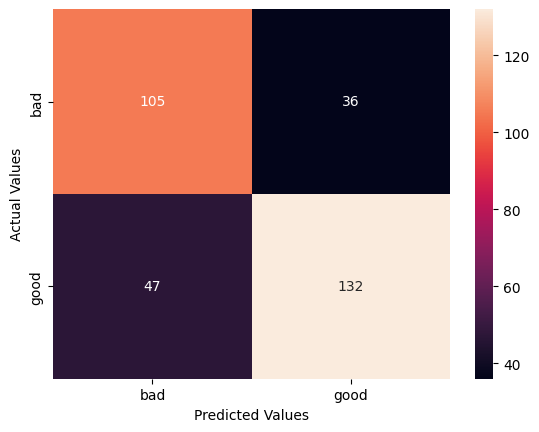

In [14]:
print("Classification Report:\n ", classification_report(y_test, y_pred_log_reg))
cm = confusion_matrix(y_test, y_pred_log_reg)
sns.heatmap(cm, annot=True, fmt = "d", xticklabels = labels, yticklabels = labels)
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

sc = accuracy_score(y_test, y_pred_log_reg)
print("Score Log Reg: ", sc)
model_scores.append(sc)

# KNN

In [15]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 1)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=1)

              precision    recall  f1-score   support

         bad       0.74      0.68      0.71       141
        good       0.76      0.81      0.79       179

    accuracy                           0.75       320
   macro avg       0.75      0.75      0.75       320
weighted avg       0.75      0.75      0.75       320

K=1 score:  0.753125


<Axes: >

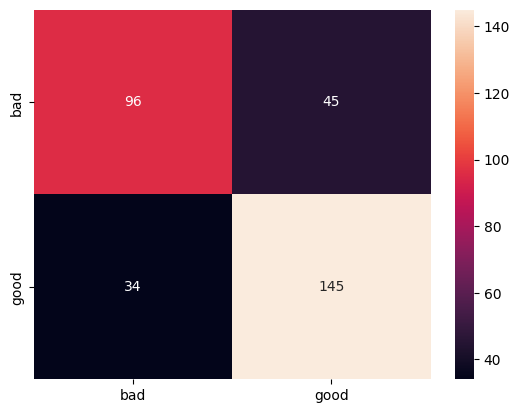

In [16]:
y1 = knn.predict(X_test)
print(classification_report(y_test, y1))
cm1 = confusion_matrix(y_test, y1)
print("K=1 score: ", knn.score(X_test, y_test))

sns.heatmap(cm1, annot=True, fmt="d", xticklabels=labels, yticklabels=labels)

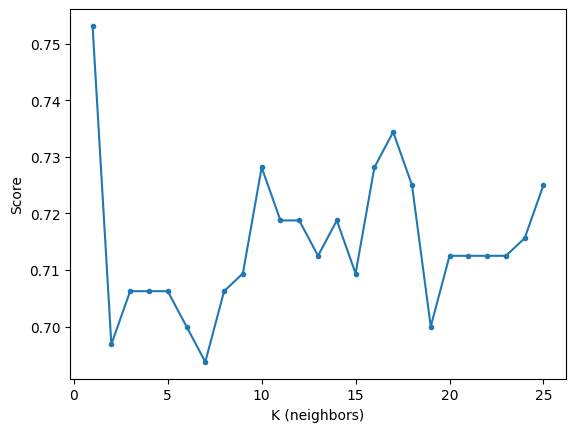

In [17]:
scores = [0]

for i in range(1, 26):
    knn_i = KNeighborsClassifier(n_neighbors = i)
    knn_i.fit(X_train, y_train)
    pred = knn_i.predict(X_test)
    score_i = accuracy_score(y_test, pred)
    scores.append(score_i)

plt.xlabel("K (neighbors)")
plt.ylabel("Score")
plt.plot(range(1, 26), scores[1:], marker='.')

# for i in range(1, 26):
#     print("K: ", i, "\tScore: ", scores[i])

In [18]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
y2 = knn.predict(X_test)
model_names.append("KNN")

accuracy_score(y_test, y2)

0.753125

              precision    recall  f1-score   support

         bad       0.74      0.68      0.71       141
        good       0.76      0.81      0.79       179

    accuracy                           0.75       320
   macro avg       0.75      0.75      0.75       320
weighted avg       0.75      0.75      0.75       320

Score KNN: 0.753125


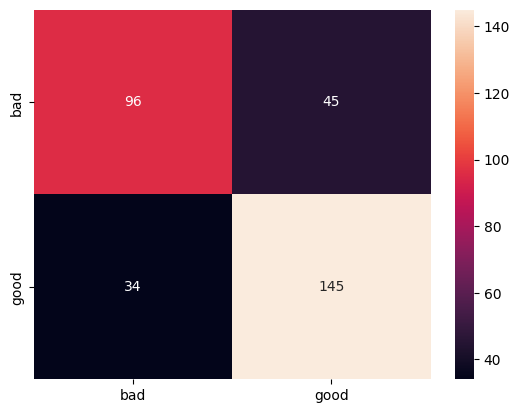

In [19]:
cm2 = confusion_matrix(y_test, y2)
sns.heatmap(cm2, annot=True, xticklabels=labels, yticklabels=labels, fmt="d")
print(classification_report(y_test, y2))
sc = accuracy_score(y_test, y1)
print("Score KNN:", sc)
model_scores.append(sc)

Text(0, 0.5, 'Model scores')

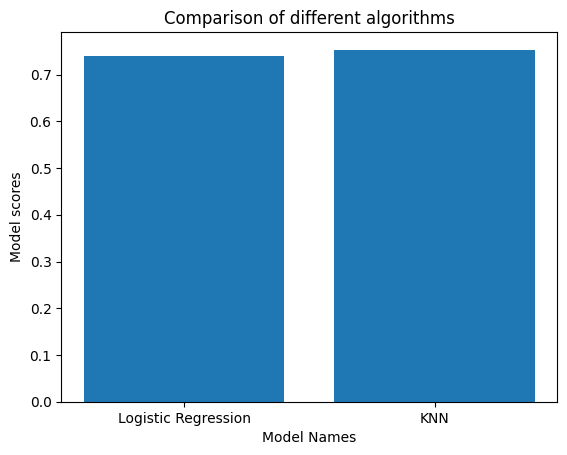

In [20]:
plt.bar(model_names, model_scores)
plt.title("Comparison of different algorithms")
plt.xlabel("Model Names")
plt.ylabel("Model scores")

In [ ]:
import joblib
 
joblib.dump(gs_cv.best_estimator_, "wine_model.pkl")   # best Logistic Regression
joblib.dump(scaler, "scaler.pkl")                      # the StandardScaler
print("Saved!")